In [7]:

import sqlite3
import pandas as pd
from google.colab import files

# Upload the SQLite database from your computer
uploaded = files.upload()

# Find the uploaded database file
db_files = [
    name for name in uploaded
    if name.lower().endswith((".db", ".sqlite", ".sqlite3"))
]

if not db_files:
    raise ValueError(
        "Please upload your SQLite database file, not the .sql or .gz file."
    )

db_path = "/content/" + db_files[0]

# Connect Python to the database
conn = sqlite3.connect(db_path)

print("Database connected successfully:", db_files[0])

# Retrieve the available tables
tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
      AND name NOT LIKE 'sqlite_%'
    ORDER BY name;
""", conn)

print("Number of tables:", len(tables))
display(tables)


Saving airline_sample.db to airline_sample (3).db
Database connected successfully: airline_sample (3).db
Number of tables: 32


,name
0,aircraft_models
1,aircrafts
2,airlines
3,airport_terminals
4,airports
5,baggage
6,baggage_rules
7,boarding_passes
8,bookings
9,cabins


In [8]:

# Verify the data inside our airline database

row_counts = pd.read_sql_query("""
SELECT 'bookings' AS table_name, COUNT(*) AS row_count
FROM bookings

UNION ALL

SELECT 'tickets', COUNT(*) FROM tickets

UNION ALL

SELECT 'ticket_flights', COUNT(*) FROM ticket_flights

UNION ALL

SELECT 'payments', COUNT(*) FROM payments

UNION ALL

SELECT 'refunds', COUNT(*) FROM refunds;
""", conn)

display(row_counts)


,table_name,row_count
0,bookings,35000
1,tickets,70000
2,ticket_flights,100000
3,payments,35000
4,refunds,500


In [9]:

# Load booking records into a Pandas DataFrame

bookings_df = pd.read_sql_query(
    "SELECT * FROM bookings;",
    conn
)

print("Number of rows:", bookings_df.shape[0])
print("Number of columns:", bookings_df.shape[1])

display(bookings_df.head())


Number of rows: 35000
Number of columns: 6


,id,booking_date,booking_reference,promotion_id,status,user_id
0,1,2023-03-26 18:41:19,BTTITR,1,confirmed,288
1,2,2021-03-11 22:49:40,GHCTFA,3,confirmed,3888
2,3,2021-01-28 21:05:49,NHALEZ,1,confirmed,121
3,4,2024-04-07 04:39:08,AWFRJH,4,confirmed,5372
4,5,2022-07-28 10:04:03,UPIAUP,1,confirmed,11


In [10]:
# Step 1: Check for missing values
print("Missing values in each column:")
display(bookings_df.isna().sum().to_frame("missing_values"))

# Step 2: Check for duplicate records
print("Exact duplicate rows:", bookings_df.duplicated().sum())

# Step 3: Check for duplicate IDs and booking references
print("Duplicate booking IDs:",
      bookings_df["id"].duplicated().sum())

print("Duplicate booking references:",
      bookings_df["booking_reference"].duplicated().sum())

# Step 4: Check whether booking dates are valid
booking_dates = pd.to_datetime(
    bookings_df["booking_date"],
    errors="coerce"
)

print("Invalid booking dates:", booking_dates.isna().sum())
print("Earliest booking date:", booking_dates.min())
print("Latest booking date:", booking_dates.max())

# Step 5: Check booking statuses
print("Booking status distribution:")
display(
    bookings_df["status"]
    .value_counts(dropna=False)
    .to_frame("record_count")
)

Missing values in each column:


,missing_values
id,0
booking_date,0
booking_reference,0
promotion_id,0
status,0
user_id,0


Exact duplicate rows: 0
Duplicate booking IDs: 0
Duplicate booking references: 0
Invalid booking dates: 0
Earliest booking date: 2020-09-10 20:25:56
Latest booking date: 2025-12-28 01:41:28
Booking status distribution:


,record_count
status,
confirmed,35000


First five months:


,booking_month,total_bookings
0,2020-09,49
1,2020-10,197
2,2020-11,487
3,2020-12,704
4,2021-01,964


Last five months:


,booking_month,total_bookings
59,2025-08,298
60,2025-09,223
61,2025-10,181
62,2025-11,107
63,2025-12,27


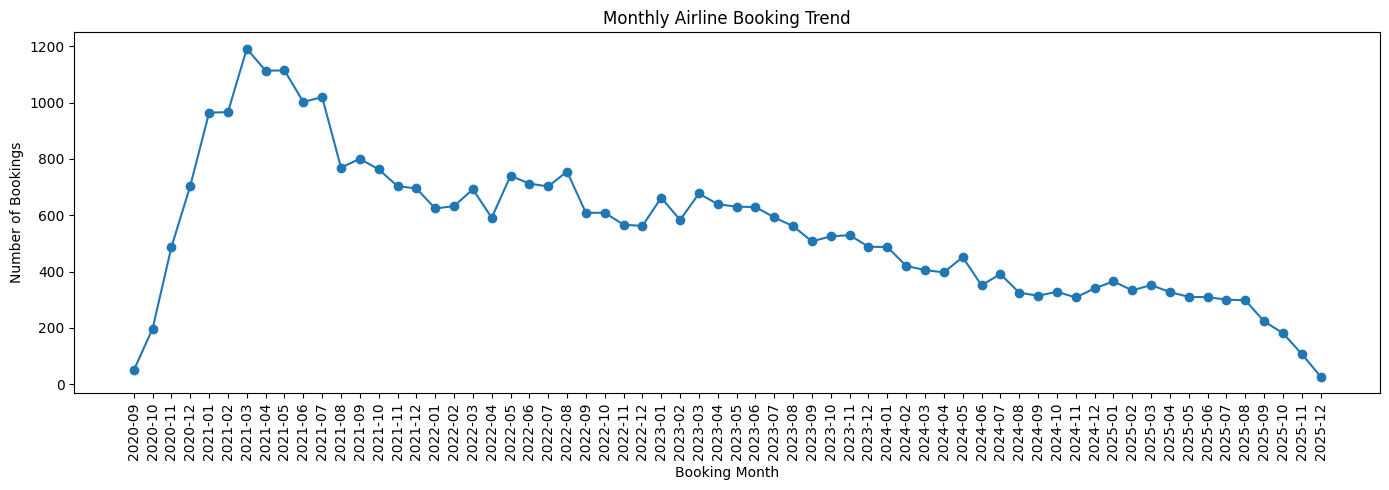

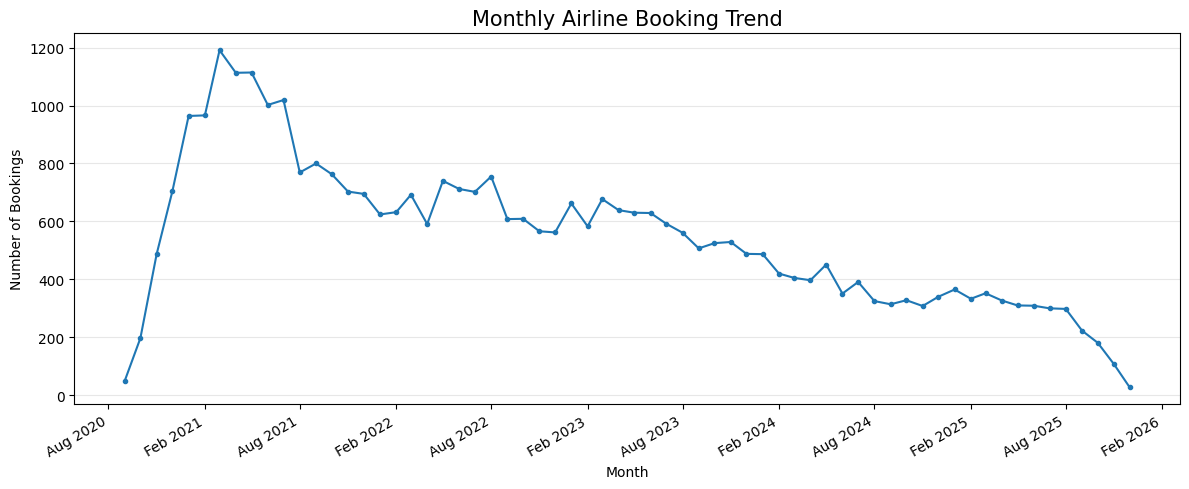

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from google.colab import files

# Convert month labels into proper dates
monthly_bookings["month_date"] = pd.to_datetime(
    monthly_bookings["booking_month"],
    format="%Y-%m"
)

# Create a cleaner chart
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_bookings["month_date"],
    monthly_bookings["total_bookings"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax.set_title("Monthly Airline Booking Trend", fontsize=15)
ax.set_xlabel("Month")
ax.set_ylabel("Number of Bookings")

# Show labels at six-month intervals
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(axis="y", alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()

# Save the chart for the portfolio
fig.savefig(
    "monthly_booking_trend.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Download the image to your computer
files.download("monthly_booking_trend.png")


In [13]:

# Load payments and refunds from the airline database

payments_df = pd.read_sql_query(
    "SELECT * FROM payments;",
    conn
)

refunds_df = pd.read_sql_query(
    "SELECT * FROM refunds;",
    conn
)

print("PAYMENTS DATA")
print("Rows and columns:", payments_df.shape)
display(payments_df.head())

print("\nREFUNDS DATA")
print("Rows and columns:", refunds_df.shape)
display(refunds_df.head())


PAYMENTS DATA
Rows and columns: (35000, 6)


,id,amount,booking_id,payment_date,payment_method,transaction_status
0,1,154.00,18367,2023-10-21 23:01:05,card,succeeded
1,2,803.70,27186,2021-03-17 00:11:18,card,succeeded
2,3,834.60,25597,2025-03-09 08:08:21,card,succeeded
3,4,156.24,8451,2023-08-31 16:59:59,card,succeeded
4,5,688.32,34346,2022-06-06 01:00:28,paypal,succeeded



REFUNDS DATA
Rows and columns: (500, 5)


,id,amount,payment_id,reason,refund_date
0,1,136.01,13398,Medical,2021-11-05 07:03:35
1,2,2412.07,10785,Schedule change,2022-11-25 13:12:34
2,3,1053.76,10204,Duplicate booking,2022-10-09 00:12:13
3,4,2399.61,12729,Medical,2022-01-07 09:38:23
4,5,2050.76,10072,Downgrade,2021-12-20 11:24:27


Payment method analysis:


,payment_method,payment_records,total_amount
2,card,24386,21492279.58
3,paypal,4959,4336898.10
0,apple_pay,4278,3824593.28
1,bank_transfer,1377,1289663.29


Refund reason analysis:


,reason,refund_records,refund_amount
0,Cancelled by customer,120,55811.87
4,Schedule change,98,60356.94
2,Duplicate booking,97,53671.90
3,Medical,93,51072.07
1,Downgrade,92,44894.75


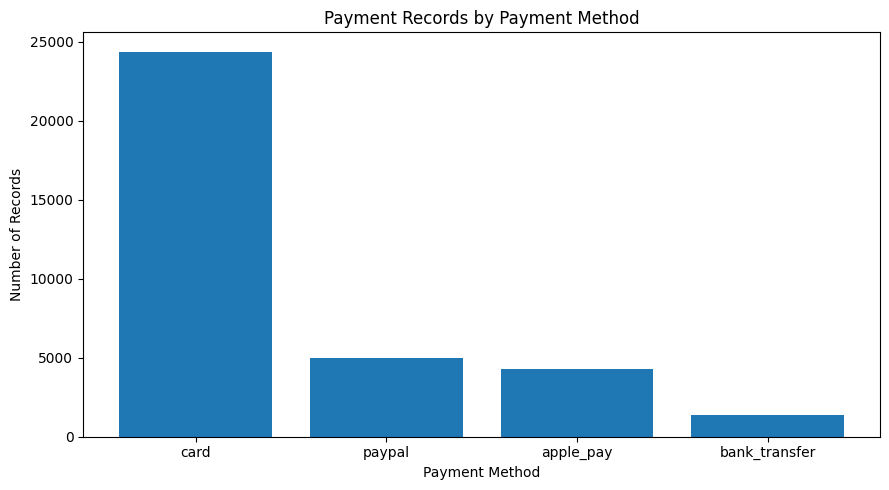

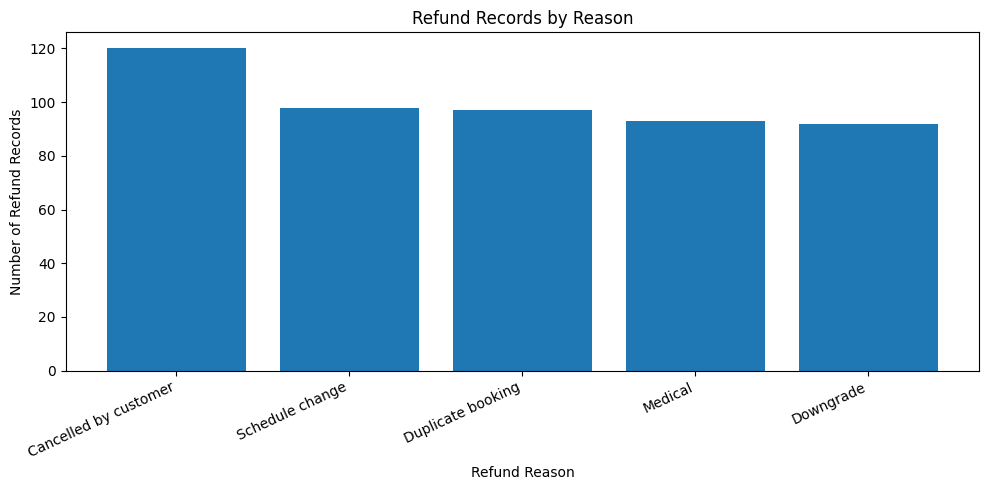

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

import matplotlib.pyplot as plt
from google.colab import files

# Summarise payment methods
payment_summary = (
    payments_df.groupby("payment_method")
    .agg(
        payment_records=("id", "count"),
        total_amount=("amount", "sum")
    )
    .reset_index()
    .sort_values("payment_records", ascending=False)
)

# Summarise refund reasons
refund_summary = (
    refunds_df.groupby("reason")
    .agg(
        refund_records=("id", "count"),
        refund_amount=("amount", "sum")
    )
    .reset_index()
    .sort_values("refund_records", ascending=False)
)

print("Payment method analysis:")
display(payment_summary.round(2))

print("Refund reason analysis:")
display(refund_summary.round(2))

# Chart 1: Payment records by method
plt.figure(figsize=(9, 5))
plt.bar(
    payment_summary["payment_method"],
    payment_summary["payment_records"]
)
plt.title("Payment Records by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig("payment_methods_analysis.png", dpi=200)
plt.show()

# Chart 2: Refund records by reason
plt.figure(figsize=(10, 5))
plt.bar(
    refund_summary["reason"],
    refund_summary["refund_records"]
)
plt.title("Refund Records by Reason")
plt.xlabel("Refund Reason")
plt.ylabel("Number of Refund Records")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("refund_reasons_analysis.png", dpi=200)
plt.show()

# Download both charts
files.download("payment_methods_analysis.png")
files.download("refund_reasons_analysis.png")


In [14]:

# Check data quality for payments and refunds

for name, df in [
    ("Payments", payments_df),
    ("Refunds", refunds_df)
]:
    print(f"\n--- {name} ---")
    print("Rows and columns:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Duplicate IDs:", df["id"].duplicated().sum())

# Check payment statuses
print("\nPayment status distribution:")
display(payments_df["transaction_status"].value_counts())

# Check payment methods
print("\nPayment method distribution:")
display(payments_df["payment_method"].value_counts())

# Check refund reasons
print("\nRefund reason distribution:")
display(refunds_df["reason"].value_counts())

# Check whether every refund refers to an existing payment
valid_payment_ids = payments_df["id"]

unmatched_refunds = (
    ~refunds_df["payment_id"].isin(valid_payment_ids)
).sum()

print("\nRefunds without a matching payment:", unmatched_refunds)



--- Payments ---
Rows and columns: (35000, 6)
Missing values: 0
Exact duplicate rows: 0
Duplicate IDs: 0

--- Refunds ---
Rows and columns: (500, 5)
Missing values: 0
Exact duplicate rows: 0
Duplicate IDs: 0

Payment status distribution:


,count
transaction_status,
succeeded,35000



Payment method distribution:


,count
payment_method,
card,24386
paypal,4959
apple_pay,4278
bank_transfer,1377



Refund reason distribution:


,count
reason,
Cancelled by customer,120
Schedule change,98
Duplicate booking,97
Medical,93
Downgrade,92



Refunds without a matching payment: 0


In [16]:

# Final financial KPI validation

gross_payments = payments_df.loc[
    payments_df["transaction_status"] == "succeeded",
    "amount"
].sum()

# Match refunds to their original payment records
refund_check = refunds_df.merge(
    payments_df[["id", "transaction_status"]],
    left_on="payment_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

refunds_linked_to_successful_payments = refund_check.loc[
    refund_check["transaction_status"] == "succeeded",
    "amount"
].sum()

total_refund_records = len(refunds_df)
net_after_refunds = (
    gross_payments - refunds_linked_to_successful_payments
)

refund_percentage = (
    refunds_linked_to_successful_payments / gross_payments * 100
    if gross_payments else 0
)

print(f"Gross successful payments: {gross_payments:,.2f}")
print(f"Total refund records: {total_refund_records:,}")
print(
    "Refund amount linked to successful payments: "
    f"{refunds_linked_to_successful_payments:,.2f}"
)
print(f"Payments after recorded refunds: {net_after_refunds:,.2f}")
print(f"Refund amount percentage: {refund_percentage:.2f}%")

# Compare against the results from our earlier SQL analysis
print("\nSQL reconciliation checks:")
print(
    "Gross payments match:",
    round(gross_payments, 2) == 30943434.25
)
print(
    "Refund amount matches:",
    round(refunds_linked_to_successful_payments, 2) == 265807.53
)
print(
    "Net amount matches:",
    round(net_after_refunds, 2) == 30677626.72
)


Gross successful payments: 30,943,434.25
Total refund records: 500
Refund amount linked to successful payments: 265,807.53
Payments after recorded refunds: 30,677,626.72
Refund amount percentage: 0.86%

SQL reconciliation checks:
Gross payments match: True
Refund amount matches: True
Net amount matches: True
